# Economic Evaluation of a Typical Oil Field Development
### A Python algorithm for computing and comparing petroleum-project economic indicators

**Research aim.** Develop a Python-based algorithm that evaluates a typical oil-field development with the standard economic indicators and compares them to identify the best development option:

| # | Topic | Section |
|---|-------|---------|
| 1 | Present value concept & discount factor | 5 |
| 2 | Net Present Value (NPV) | 6 |
| 3 | Internal Rate of Return (IRR) — including multiple-IRR detection and MIRR | 7 |
| 4 | Payback period (simple & discounted) | 8 |
| 5 | Profit / investment ratio (profitability index) | 9 |
| 6 | Effect of the start-up date | 12 |
| 7 | Incremental projects (mutually exclusive alternatives) | 13–14 |
| 8 | Comparison of all indicators → best option | 15 |
| + | Sensitivity (spider / tornado) using the ranges in your template | 16 |

**How to use**

1. Run the notebook from the top. **The first thing it does is ask you to select your dataset** (Excel file in the standard *Economic Evaluation Study* template, sheet `Input&Output`).
   * Google Colab → an upload button appears.
   * Local Jupyter / Python with a display → a file-browser window opens.
   * Remote / headless → you are asked to type the file path.
2. Everything downstream (cash flow, indicators, alternatives, plots, results workbook) is computed from that file.
3. Optional model switches are in the **CONFIG** cell (Section 1). The defaults reproduce the calculation logic of the template workbook exactly.

## 1. Imports and configuration
`CONFIG` holds every switch that is *not* in your Excel template. Defaults replicate the workbook's own logic, so the notebook first reproduces your workbook results (Section 10 checks this) before going further.

In [1]:
import os
import re
import warnings
from dataclasses import dataclass, field, replace, fields

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import load_workbook

try:                                   # xlrd is needed to read the raw .xls (Excel 97-2003) dataset
    import xlrd
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])
    import xlrd

try:                                   # nicer tables inside Jupyter / Colab
    from IPython.display import display
except ImportError:                    # plain python fallback
    display = print

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 200
pd.options.display.max_columns = 40
plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3})

# ----------------------------------------------------------------------------
# CONFIG  -  model switches that are NOT part of the Excel template
# ----------------------------------------------------------------------------
CONFIG = {
    # ---- fiscal / cash-flow behaviour (defaults = template workbook logic) ----
    "APPLY_PRICE_ESCALATION": False,   # template lists 2 %/yr oil escalation but its revenue formula does NOT use it.
                                       # False = reproduce workbook; True = apply escalation to oil/gas prices.
    "ECONOMIC_LIMIT_CUTOFF": False,    # False = produce for the full project life (template: 20 yrs, no abandonment).
                                       # True  = abandon when operating margin (revenue - opex) first turns negative.
    "LOSS_CARRY_FORWARD": False,       # template taxes max(0, taxable income) each year (no loss carry-forward)
    "DB_FACTOR": 1.5,                  # declining-balance rate = DB_FACTOR / N   (150 % DB)
    "DDB_FACTOR": 2.0,                 # double-declining-balance rate = DDB_FACTOR / N
    "PAYBACK_LIMIT_YEARS": 10,         # template flags payback "OK" when < 10 years

    # ---- start-up date analysis ----
    "STARTUP_DELAYS": [0, 1, 2, 3, 4, 5],  # years of delay to test (0 = on time)
    "INFLATE_DURING_DELAY": True,      # opex keeps inflating while the project waits (real-world cost of delay)
    "CAPEX_ESCALATION": 0.0,           # capex inflation per year of delay (fraction; template has none)

    # ---- alternatives for incremental analysis ----
    # The template describes ONE development. Mutually exclusive alternatives are generated by scaling
    # the number of wells (development size). Edit the list, or supply CUSTOM_ALTERNATIVES below.
    "DEVELOPMENT_SCALES": [0.6, 0.8, 1.0, 1.2, 1.5, 2.0],   # 1.0 = the template case itself
    "FACILITY_SCALING_EXPONENT": 0.6,      # facilities, camp, pipelines, fixed opex scale with size^0.6 (six-tenths rule)
    "RESERVOIR_RESPONSE_EXPONENT": 0.85,   # oil rate scales with wells^0.85 (well interference / diminishing returns)
                                           #   set to 1.0 for perfectly proportional production
    "CUSTOM_ALTERNATIVES": {},             # e.g. {"Small": {"wells": 15, "q1_mbd": 11, "facilities": 30}}
                                           #   keys must be ProjectInputs fields (see Section 3). If non-empty it
                                           #   replaces the scale-generated list (template case always included).
    "CAPITAL_BUDGET": None,                # $MM; alternatives with capex above this are excluded. None = unlimited

    # ---- plotting / output ----
    "NPV_PROFILE_MAX_RATE": 0.50,          # upper discount rate shown in NPV profiles
    "SAVE_RESULTS": True,
    "RESULTS_FILE": "Economic_Indicators_Results.xlsx",
}
print("Configuration loaded. Edit CONFIG above to change model switches.")

Configuration loaded. Edit CONFIG above to change model switches.


## 2. Select the dataset (prompted first)
The function below opens an upload button (Colab), a file-browser window (desktop) or a text prompt (remote/headless).
The file must follow the standard template: a sheet named **`Input&Output`** with the labelled input rows.

In [2]:
def select_dataset():
    '''Ask the user to choose the Excel dataset.  Tries, in order:
       1) Google Colab upload widget, 2) native file-browser dialog, 3) typed file path.
       Returns the path of the chosen file.'''
    print("=" * 70)
    print(" SELECT YOUR DATASET  (Excel file in the 'Economic Evaluation Study' template)")
    print("=" * 70)

    # 1) Google Colab -> upload widget
    try:
        from google.colab import files            # only exists inside Colab
        uploaded = files.upload()
        if uploaded:
            return next(iter(uploaded))            # Colab saves the upload in the working directory
        print("No file uploaded.")
    except ImportError:
        pass

    # 2) Desktop -> native file-browser dialog (tkinter ships with most Python installs)
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)          # bring the dialog to the front
        path = filedialog.askopenfilename(
            title="Select the oil-field economics dataset",
            filetypes=[("Excel workbook", "*.xlsx *.xlsm *.xls"), ("All files", "*.*")])
        root.destroy()
        if path:
            return path
        print("No file chosen in the dialog.")
    except Exception:
        print("(File dialog not available in this environment - please type the path.)")

    # 3) Fallback -> typed path
    while True:
        path = input("Full path of the .xlsx / .xls dataset (or 'q' to cancel): ").strip().strip('"').strip("'")
        if path.lower() in ("q", "quit", "exit"):
            raise RuntimeError("Dataset selection cancelled by user.")
        if os.path.isfile(path):
            return path
        print(f"  File not found: {path!r}. Try again.")


DATASET_PATH = select_dataset()
print(f"\nDataset selected: {DATASET_PATH}")

 SELECT YOUR DATASET  (Excel file in the 'Economic Evaluation Study' template)


Saving Economics Indicators.xlsx to Economics Indicators.xlsx

Dataset selected: Economics Indicators.xlsx


## 2b. Output folder (saves everything next to the dataset)
Creates a folder **in the same location as the Excel dataset you just selected** and, from this point on, automatically saves:
* every **plot** (PNG, 150 dpi),
* every **table** shown with `display()` (CSV),
* the full **console text** of the run (`run_log.txt`),
* the **results workbook** (`Economic_Indicators_Results.xlsx`, Section 17).

No later cell is changed - the saving is done by hooks installed here. The last cell of the notebook (Section 18) writes the extra files and closes the log.

In [ ]:
import sys, io, shutil, datetime

# ---- output folder: same directory as the selected Excel dataset ----
DATASET_DIR = os.path.dirname(os.path.abspath(DATASET_PATH))
_stem = os.path.splitext(os.path.basename(DATASET_PATH))[0]
OUTPUT_DIR = os.path.join(DATASET_DIR, f"{_stem}_output")
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
for _d in (OUTPUT_DIR, FIG_DIR, TABLE_DIR):
    os.makedirs(_d, exist_ok=True)

# Section 17 writes the results workbook to CONFIG["RESULTS_FILE"] -> point it into the output folder
CONFIG["RESULTS_FILE"] = os.path.join(OUTPUT_DIR, os.path.basename(CONFIG["RESULTS_FILE"]))


def _slug(text, default="item"):
    s = re.sub(r"[^A-Za-z0-9]+", "_", str(text)).strip("_")
    return (s[:60] or default)


# ---- 1) every figure shown with plt.show() is also saved as PNG ----
_fig_counter = {"n": 0}
_orig_show = plt.show

def _show_and_save(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        _fig_counter["n"] += 1
        title = fig.axes[0].get_title().split("\n")[0] if fig.axes else ""
        fname = f"fig_{_fig_counter['n']:02d}_{_slug(title, 'figure')}.png"
        fig.savefig(os.path.join(FIG_DIR, fname), dpi=150, bbox_inches="tight")
    return _orig_show(*args, **kwargs)

plt.show = _show_and_save


# ---- 2) every table shown with display() is also saved as CSV ----
_tbl_counter = {"n": 0}
_orig_display = display

def _display_and_save(obj=None, *args, **kwargs):
    if isinstance(obj, (pd.DataFrame, pd.Series)):
        _tbl_counter["n"] += 1
        df = obj.to_frame() if isinstance(obj, pd.Series) else obj
        first = next(iter(df.columns), "table")
        fname = f"table_{_tbl_counter['n']:02d}_{_slug(first, 'table')}.csv"
        df.to_csv(os.path.join(TABLE_DIR, fname))
    return _orig_display(obj, *args, **kwargs)

display = _display_and_save


# ---- 3) everything printed is also written to run_log.txt ----
class _Tee(io.TextIOBase):
    def __init__(self, stream, log):
        self._stream, self._log = stream, log
    def write(self, s):
        self._log.write(s)
        return self._stream.write(s)
    def flush(self):
        self._log.flush()
        self._stream.flush()
    def __getattr__(self, name):                     # behave like the wrapped stream
        return getattr(self._stream, name)

_log_file = open(os.path.join(OUTPUT_DIR, "run_log.txt"), "w", encoding="utf-8")
_orig_stdout = sys.stdout
sys.stdout = _Tee(_orig_stdout, _log_file)

print(f"Output folder: {OUTPUT_DIR}")
print(f"  figures/ -> plots (PNG)   tables/ -> displayed tables (CSV)   run_log.txt -> console output")
print(f"  Run started {datetime.datetime.now():%Y-%m-%d %H:%M:%S}")


## 3. Read and validate the template
The reader locates each input **by its label** in column A (values in column D, inflation/escalation rates in column G), so it keeps working if rows are inserted or moved slightly. It also reads:

* the selected **depreciation method** (the cell marked `1` under the method names),
* the **project life** from the text “Project life = 20 years”,
* the **sensitivity ranges** (from / to, in %),
* the **results already computed in the workbook** (NPV, IRR, payback, CPI) — used in Section 10 to prove the Python model reproduces your Excel model.

In [3]:
@dataclass
class ProjectInputs:
    '''All inputs of one field-development project (units follow the template).'''
    name: str = "Template case"
    # production
    q1_mbd: float = 0.0          # oil rate in year 1, thousand barrels/day (MBD)
    decline: float = 0.0         # annual decline (fraction)
    gor: float = 0.0             # gas-oil ratio, SCF/STB
    # investment
    wells: float = 0.0
    drill_cost: float = 0.0      # $MM/well
    pipe_len: float = 0.0        # km
    d_crude: float = 0.0         # inches
    d_gas: float = 0.0           # inches
    pipe_unit_cost: float = 0.0  # $/inch-km
    facilities: float = 0.0      # $MM
    camp: float = 0.0            # $MM
    # operating cost (year-0 basis) and inflation (fractions per year)
    fuel: float = 0.0;        fuel_infl: float = 0.0          # $MM/yr
    spares: float = 0.0;      spares_infl: float = 0.0        # $MM/yr
    maint: float = 0.0;       maint_infl: float = 0.0         # $MM/yr
    salary: float = 0.0;      salary_infl: float = 0.0        # $/person/month
    catering: float = 0.0;    catering_infl: float = 0.0      # $/person/day
    overhead: float = 0.0;    overhead_infl: float = 0.0      # $MM/yr
    well_serv: float = 0.0;   well_serv_infl: float = 0.0     # $MM/yr/well
    personnel: float = 0.0
    # cash-flow data
    oil_price: float = 0.0;   oil_esc: float = 0.0            # $/bbl , escalation fraction/yr
    gas_price: float = 0.0;   gas_esc: float = 0.0            # $/MCF
    tax: float = 0.0                                          # fraction
    disc: float = 0.0                                         # discount rate, fraction
    # depreciation
    dep_method: str = "SL"       # SL, DBwB, DB, DDBwB, DDB, SYD, UOP
    dep_years: int = 10
    salvage: float = 0.0         # $MM
    life: int = 20               # project life, years
    # extras read from the template
    sens: dict = field(default_factory=dict)              # {"Production Rate": (lo, hi), ...} fractions
    template_results: dict = field(default_factory=dict)  # values already computed inside the workbook


# (attribute, label in column A, column with the value, multiplier)   column 4 = D, column 7 = G
_INPUT_MAP = [
    ("q1_mbd", "Oil production rate in year 1", 4, 1), ("decline", "Decline rate", 4, 0.01),
    ("gor", "Gas Oil Ratio", 4, 1),
    ("wells", "Number of wells", 4, 1), ("drill_cost", "Drilling cost", 4, 1),
    ("pipe_len", "Length of pipelines", 4, 1), ("d_crude", "Diameter of crude pipeline", 4, 1),
    ("d_gas", "Diameter of gas pipeline", 4, 1), ("pipe_unit_cost", "Cost of pipeline", 4, 1),
    ("facilities", "Cost of production facilities", 4, 1), ("camp", "Cost of camp", 4, 1),
    ("fuel", "Fuel", 4, 1), ("spares", "Spare parts", 4, 1), ("maint", "Maintenance Requirements", 4, 1),
    ("salary", "Salaries", 4, 1), ("catering", "Catering & Services", 4, 1),
    ("overhead", "Overhead costs", 4, 1), ("well_serv", "Well services & workovers", 4, 1),
    ("personnel", "Number of personnel", 4, 1),
    ("oil_price", "Crude selling Price", 4, 1), ("gas_price", "Gas selling Price", 4, 1),
    ("tax", "Tax rate", 4, 0.01), ("disc", "Discount Rate", 4, 0.01),
    ("dep_years", "Number of Years", 4, 1),
]
# optional rate columns (blank -> 0):  inflation for opex items, escalation for prices (column G)
_RATE_MAP = [
    ("fuel_infl", "Fuel"), ("spares_infl", "Spare parts"), ("maint_infl", "Maintenance Requirements"),
    ("salary_infl", "Salaries"), ("catering_infl", "Catering & Services"), ("overhead_infl", "Overhead costs"),
    ("well_serv_infl", "Well services & workovers"), ("oil_esc", "Crude selling Price"), ("gas_esc", "Gas selling Price"),
]
_DEP_HEADERS = {"str. line": "SL", "dbw/b": "DBwB", "db": "DB", "ddbw/b": "DDBwB",
                "ddb": "DDB", "s.y.d": "SYD", "unt. prod": "UOP"}
DEP_NAMES = {"SL": "Straight line", "DBwB": "Declining balance w/ balloon", "DB": "Declining balance",
             "DDBwB": "Double declining w/ balloon", "DDB": "Double declining balance",
             "SYD": "Sum-of-years-digits", "UOP": "Unit of production"}


def _norm(s):
    '''Normalise a label: lower case, single spaces (makes label matching tolerant).'''
    return re.sub(r"\s+", " ", str(s)).strip().lower()


class _XlsSheet:
    '''Minimal read-only wrapper so an .xls sheet (xlrd) behaves like an openpyxl sheet:
    ws.max_row and ws.cell(row, col).value with 1-based indices.'''
    class _Cell:
        __slots__ = ("value",)
        def __init__(self, value):
            self.value = value
    def __init__(self, sheet):
        self._s = sheet
        self.max_row = sheet.nrows
    def cell(self, r, c):
        if r > self._s.nrows or c > self._s.ncols:
            return self._Cell(None)
        cell = self._s.cell(r - 1, c - 1)
        if cell.ctype in (xlrd.XL_CELL_EMPTY, xlrd.XL_CELL_BLANK, xlrd.XL_CELL_ERROR) or cell.value == "":
            # (error cells such as #NUM! / #DIV/0! in an uncalculated raw workbook count as empty)
            return self._Cell(None)
        return self._Cell(cell.value)


def open_input_sheet(path):
    '''Open the 'Input&Output' sheet of an .xlsx/.xlsm (openpyxl) or raw .xls (xlrd) workbook.'''
    if os.path.splitext(path)[1].lower() == ".xls":
        wb = xlrd.open_workbook(path)
        names = wb.sheet_names()
        get = lambda n: _XlsSheet(wb.sheet_by_name(n))
    else:
        wb = load_workbook(path, data_only=True)   # data_only -> also gives the workbook's own results
        names = wb.sheetnames
        get = lambda n: wb[n]
    sheet = next((n for n in names if _norm(n) == "input&output"), None)
    if sheet is None:
        raise ValueError(f"Sheet 'Input&Output' not found. Sheets in file: {names}. "
                         "The dataset must follow the standard template.")
    return get(sheet)


def read_template(path):
    '''Read the standard template and return a validated ProjectInputs object.'''
    ws = open_input_sheet(path)

    # map: normalised label (column A) -> list of row numbers
    rows = {}
    for r in range(1, ws.max_row + 1):
        v = ws.cell(r, 1).value
        if v is not None:
            rows.setdefault(_norm(v), []).append(r)

    def row_of(label, after=0):
        for r in rows.get(_norm(label), []):
            if r > after:
                return r
        return None

    def number(cell):
        return float(cell) if isinstance(cell, (int, float)) and not isinstance(cell, bool) else None

    p, missing = ProjectInputs(), []
    for attr, label, col, mult in _INPUT_MAP:                    # 1) mandatory numeric inputs
        r = row_of(label)
        val = number(ws.cell(r, col).value) if r else None
        if val is None:
            missing.append(f"{label!r} (expected a number in column {'D' if col == 4 else col}, row {r})")
        else:
            setattr(p, attr, val * mult)
    for attr, label in _RATE_MAP:                                # 2) optional inflation / escalation (col G)
        r = row_of(label)
        val = number(ws.cell(r, 7).value) if r else None
        setattr(p, attr, (val or 0.0) / 100.0)
    if missing:
        raise ValueError("Dataset does not match the template. Problem inputs:\n  - " + "\n  - ".join(missing))

    r = row_of("Salvage Value")                                  # 3) salvage value (blank -> 0)
    p.salvage = (number(ws.cell(r, 4).value) or 0.0) if r else 0.0

    r = row_of("Depreciation Method")                            # 4) depreciation method marked with 1
    chosen = []
    if r:
        for c in range(4, 11):
            hdr = _norm(ws.cell(r, c).value or "")
            mark = ws.cell(r + 1, c).value
            if hdr in _DEP_HEADERS and mark == 1:
                chosen.append(_DEP_HEADERS[hdr])
    if len(chosen) != 1:
        print(f"  ! Depreciation method: found {len(chosen)} marks -> using straight line.")
        chosen = ["SL"]
    p.dep_method = chosen[0]
    p.dep_years = int(p.dep_years)

    p.life = 20                                                  # 5) project life from free text
    for r_ in range(1, ws.max_row + 1):
        m = re.search(r"project\s*life\s*=\s*(\d+)", str(ws.cell(r_, 1).value or ""), re.I)
        if m:
            p.life = int(m.group(1))
            break
    else:
        print("  ! 'Project life = N years' not found -> assuming 20 years.")

    hdr_row = next((r_ for r_ in range(1, ws.max_row + 1)        # 6) sensitivity ranges (%)
                    if re.match(r"\s*s[ie]n[sc]?[is]tiv", str(ws.cell(r_, 1).value or ""), re.I)), None)
    if hdr_row:
        for label in ("Production Rate", "Capex", "Opex", "Oil Price"):
            r = row_of(label, after=hdr_row)
            lo, hi = (number(ws.cell(r, 3).value), number(ws.cell(r, 5).value)) if r else (None, None)
            if lo is not None and hi is not None:
                p.sens[label] = (lo / 100.0, hi / 100.0)

    for key, label in (("NPV", "Net Present Value (NPV)"), ("IRR", "Internal Rate of Return (IRR)"),
                       ("Payback", "Payback Period (Payout)"), ("CPI", "Capital Productivity Index (CPI)")):
        for r_ in range(1, ws.max_row + 1):                      # 7) results stored in the workbook
            if _norm(ws.cell(r_, 4).value or "") == _norm(label):
                val = number(ws.cell(r_, 8).value)
                if val is not None:
                    p.template_results[key] = val
    if len(p.template_results) < 4:      # raw data: result cells are empty / 0 placeholders (workbook not calculated)
        p.template_results = {}          # -> nothing to verify against; results come from the Python model only

    m = re.search(r"\(([^)]*)\)", str(ws.cell(2, 1).value or ""))     # 8) field name from title (optional)
    p.name = (m.group(1).strip() if m and m.group(1).strip() else "Base")
    if p.life < 1 or p.dep_years < 1:
        raise ValueError("Project life and depreciation years must be >= 1.")
    return p


def capex_breakdown(p):
    '''Investment ($MM): drilling + pipelines + facilities + camp (all spent at year 0, as in the template).'''
    drilling = p.wells * p.drill_cost
    pipelines = p.pipe_len * (p.d_crude + p.d_gas) * p.pipe_unit_cost / 1e6
    return {"Drilling": drilling, "Pipelines": pipelines, "Production facilities": p.facilities,
            "Camp": p.camp, "TOTAL CAPEX": drilling + pipelines + p.facilities + p.camp}


base_inputs = read_template(DATASET_PATH)
DISC = base_inputs.disc                                # project discount rate (fraction)

print(f"Project           : {base_inputs.name} development   |  life = {base_inputs.life} yr  |  "
      f"discount rate = {DISC:.1%}  |  tax = {base_inputs.tax:.0%}")
print(f"Production        : {base_inputs.q1_mbd} MBD in year 1, {base_inputs.decline:.0%} annual decline, "
      f"GOR {base_inputs.gor:,.0f} SCF/STB")
print(f"Depreciation      : {DEP_NAMES[base_inputs.dep_method]} over {base_inputs.dep_years} years "
      f"(salvage {base_inputs.salvage} $MM)")
print(f"Prices            : oil {base_inputs.oil_price} $/bbl (esc {base_inputs.oil_esc:.0%}), "
      f"gas {base_inputs.gas_price} $/MCF (esc {base_inputs.gas_esc:.0%})")
print("Sensitivity ranges:", {k: f"{lo:+.0%} to {hi:+.0%}" for k, (lo, hi) in base_inputs.sens.items()})
print("\nInvestment breakdown ($MM):")
display(pd.Series(capex_breakdown(base_inputs), name="$MM").to_frame())

Project           : Base development   |  life = 20 yr  |  discount rate = 10.0%  |  tax = 40%
Production        : 20.0 MBD in year 1, 5% annual decline, GOR 1,500 SCF/STB
Depreciation      : Straight line over 10 years (salvage 0.0 $MM)
Prices            : oil 20.0 $/bbl (esc 2%), gas 1.5 $/MCF (esc 0%)
Sensitivity ranges: {'Production Rate': '-10% to +10%', 'Capex': '-30% to +20%', 'Opex': '-20% to +40%', 'Oil Price': '-25% to +30%'}

Investment breakdown ($MM):


,$MM
Drilling,150.000
Pipelines,9.000
Production facilities,50.000
Camp,10.000
TOTAL CAPEX,219.000


## 4. Cash-flow model
For every project year *t* (year 0 = investment, years 1…N = production):

```
Oil (MMB)      = q1 x 365/1000 x (1 - decline)^(t-1)            Gas (BCF) = Oil x GOR / 1000
Revenue        = Oil price x Oil + Gas price x Gas               (price escalation optional, see CONFIG)
Opex           = Σ  item_year0 x (1 + inflation_item)^t          (fuel, spares, maintenance, salaries, catering, overhead, well services)
Depreciation   = chosen method on CAPEX (SL, DB, DDB, with/without balloon, SYD, unit-of-production)
Taxable income = Revenue - Opex - Depreciation        Tax = tax rate x max(0, taxable income)   (loss carry-forward optional)
Net cash flow  = Revenue - CAPEX - Opex - Tax
```
The function also accepts a **start-up delay** and **multipliers** (production, capex, opex, price) used later for the start-up-date and sensitivity analyses.

In [4]:
def depreciation_schedule(capex, method, n, salvage, production=None, life=None,
                          db_factor=1.5, ddb_factor=2.0):
    '''Depreciation charge for project years 0..life (index 0 = 0).
    SL   straight line                     (capex - salvage) / n
    DB   declining balance                 rate = db_factor / n on book value, never below salvage
    DDB  double declining balance          rate = ddb_factor / n
    xxwB "with balloon": the undepreciated balance is written off in the last year n
         (without balloon the remaining book value is simply not depreciated)
    SYD  sum-of-years-digits               (capex - salvage) x (n - t + 1) / (n(n+1)/2)
    UOP  unit of production                (capex - salvage) x production_t / total production
    '''
    life = life if life is not None else n
    n = int(min(n, life))
    dep = np.zeros(life + 1)
    base = max(capex - salvage, 0.0)
    if method == "SL":
        dep[1:n + 1] = base / n
    elif method in ("DB", "DBwB", "DDB", "DDBwB"):
        rate = (db_factor if method.startswith("DB") else ddb_factor) / n
        book = capex
        for t in range(1, n + 1):
            d = min(rate * book, book - salvage)         # cannot depreciate below salvage value
            if method.endswith("wB") and t == n:
                d = book - salvage                        # balloon: write off the remainder
            dep[t] = max(d, 0.0)
            book -= dep[t]
    elif method == "SYD":
        syd = n * (n + 1) / 2.0
        for t in range(1, n + 1):
            dep[t] = base * (n - t + 1) / syd
    elif method == "UOP":
        prod = np.asarray(production, float)
        prod[0] = 0.0
        dep[1:] = base * prod[1:] / prod[1:].sum() if prod[1:].sum() > 0 else 0.0
    else:
        raise ValueError(f"Unknown depreciation method {method!r}")
    return dep


def build_cash_flow(p, startup_delay=0, mult=None, cfg=None):
    '''Annual cash-flow table ($MM) for project inputs `p`.
      startup_delay : years between today (evaluation date, year 0) and sanction/investment.
      mult          : sensitivity multipliers, keys 'prod','capex','opex','price' (default 1.0 each).
      cfg           : CONFIG-style dict (defaults to the global CONFIG).
    Column `Year` = calendar years from today (discounting basis); `ProjYear` = years from investment.'''
    cfg = cfg or CONFIG
    m = {"prod": 1.0, "capex": 1.0, "opex": 1.0, "price": 1.0, **(mult or {})}
    d, N = int(startup_delay), int(p.life)
    year = np.arange(0, N + d + 1)
    tp = year - d                                    # project year (negative while waiting)
    producing = tp >= 1
    # index used for inflation / escalation: calendar years if costs keep inflating during a delay
    idx = np.maximum(year if cfg["INFLATE_DURING_DELAY"] else tp, 0)
    pidx = idx if cfg["APPLY_PRICE_ESCALATION"] else np.zeros_like(idx)

    # ---- production ----
    oil = np.where(producing, p.q1_mbd * 365 / 1000 * m["prod"] * (1 - p.decline) ** (np.maximum(tp, 1) - 1), 0.0)
    gas = oil * p.gor / 1000.0                       # BCF
    # ---- revenue ----
    oil_rev = p.oil_price * m["price"] * (1 + p.oil_esc) ** pidx * oil
    gas_rev = p.gas_price * (1 + p.gas_esc) ** pidx * gas
    revenue = oil_rev + gas_rev
    # ---- operating cost items ($MM/yr, inflated from year-0 basis) ----
    g = lambda base, infl: np.where(producing, base * (1 + infl) ** idx, 0.0) * m["opex"]
    items = {
        "Fuel": g(p.fuel, p.fuel_infl),
        "Spares": g(p.spares, p.spares_infl),
        "Maintenance": g(p.maint, p.maint_infl),
        "Salaries": g(p.salary * p.personnel * 12 / 1e6, p.salary_infl),
        "Catering": g(p.catering * p.personnel * 365 / 1e6, p.catering_infl),
        "Overhead": g(p.overhead, p.overhead_infl),
        "Well services": g(p.wells * p.well_serv, p.well_serv_infl),
    }
    opex = sum(items.values())
    # ---- optional economic-limit abandonment ----
    if cfg["ECONOMIC_LIMIT_CUTOFF"]:
        neg = np.where(producing & (revenue - opex < 0))[0]
        if len(neg):
            k = neg[0]
            for arr in (oil, gas, oil_rev, gas_rev, revenue, opex, *items.values()):
                arr[k:] = 0.0
    # ---- capex (all at investment year, as in template) ----
    capex_total = capex_breakdown(p)["TOTAL CAPEX"] * m["capex"] * (1 + cfg["CAPEX_ESCALATION"]) ** d
    capex = np.where(tp == 0, capex_total, 0.0)
    # ---- depreciation ----
    dep = np.zeros(len(year))
    dep[d:] = depreciation_schedule(capex_total, p.dep_method, p.dep_years, p.salvage,
                                    production=oil[d:], life=N,
                                    db_factor=cfg["DB_FACTOR"], ddb_factor=cfg["DDB_FACTOR"])
    # ---- tax ----
    taxable = revenue - opex - dep
    if cfg["LOSS_CARRY_FORWARD"]:
        tax, loss = np.zeros(len(year)), 0.0
        for i, ti in enumerate(taxable):
            if ti < 0:
                loss += -ti
            else:
                used = min(loss, ti)
                loss -= used
                tax[i] = (ti - used) * p.tax
    else:
        tax = np.maximum(0.0, taxable) * p.tax
    ncf = revenue - capex - opex - tax

    out = pd.DataFrame({"Year": year, "ProjYear": tp, "Oil_MMB": oil, "Gas_BCF": gas,
                        "Oil_Rev": oil_rev, "Gas_Rev": gas_rev, "Revenue": revenue, "CAPEX": capex,
                        **items, "OPEX": opex, "Depreciation": dep, "Taxable_Income": taxable,
                        "Tax": tax, "NCF": ncf})
    out["Cum_NCF"] = out["NCF"].cumsum()
    return out


base_cf = build_cash_flow(base_inputs)
print(f"Base-case cash flow ($MM)  -  {len(base_cf) - 1} years, depreciation = {DEP_NAMES[base_inputs.dep_method]}")
show = ["Year", "Oil_MMB", "Gas_BCF", "Revenue", "CAPEX", "OPEX", "Depreciation", "Tax", "NCF", "Cum_NCF"]
display(base_cf[show].round(3))
print("Column totals:")
display(base_cf[["Oil_MMB", "Gas_BCF", "Revenue", "CAPEX", "OPEX", "Depreciation", "Tax", "NCF"]].sum().round(3).to_frame("Total").T)

Base-case cash flow ($MM)  -  20 years, depreciation = Straight line


,Year,Oil_MMB,Gas_BCF,Revenue,CAPEX,OPEX,Depreciation,Tax,NCF,Cum_NCF
0,0,0.000,0.000,0.000,219.000,0.000,0.000,0.000,-219.000,-219.000
1,1,7.300,10.950,162.425,0.000,46.483,21.900,37.617,78.325,-140.675
2,2,6.935,10.402,154.304,0.000,49.620,21.900,33.114,71.570,-69.104
3,3,6.588,9.882,146.589,0.000,52.976,21.900,28.685,64.927,-4.177
4,4,6.259,9.388,139.259,0.000,56.568,21.900,24.317,58.375,54.198
5,5,5.946,8.919,132.296,0.000,60.411,21.900,19.994,51.891,106.089
6,6,5.649,8.473,125.681,0.000,64.524,21.900,15.703,45.454,151.543
7,7,5.366,8.049,119.397,0.000,68.927,21.900,11.428,39.042,190.586
8,8,5.098,7.647,113.427,0.000,73.640,21.900,7.155,32.633,223.218
9,9,4.843,7.264,107.756,0.000,78.685,21.900,2.869,26.203,249.421


Column totals:


,Oil_MMB,Gas_BCF,Revenue,CAPEX,OPEX,Depreciation,Tax,NCF
Total,93.661,140.492,"2,083.958",219.000,"1,873.572",219.000,183.832,-192.446


## 5. Present value concept and discount factor
Money received later is worth less than money received today because it could be invested at the discount rate *i*. The **discount factor** converts a cash flow in year *t* to today's money (year 0):

$$DF_t = \frac{1}{(1+i)^t} \qquad\qquad PV_t = CF_t \times DF_t \qquad\qquad FV_t = PV \times (1+i)^t$$

Year 0 (the investment / evaluation date) has DF = 1.

$100 MM received in year 5, discounted at 10%:
   discount factor = 0.6209   ->   present value = 62.09 $MM
   (equivalently, $100 MM today grows to 161.05 $MM in 5 years)

Discount-factor table:


,Year,DF @ 5%,DF @ 10%,DF @ 15%,DF @ 20%
0,0,1.000,1.000,1.000,1.000
1,1,0.952,0.909,0.870,0.833
2,2,0.907,0.826,0.756,0.694
3,3,0.864,0.751,0.657,0.579
4,4,0.823,0.683,0.572,0.482
5,5,0.783,0.621,0.497,0.402
6,6,0.746,0.565,0.432,0.335
7,7,0.711,0.513,0.376,0.279
8,8,0.677,0.467,0.327,0.233
9,9,0.645,0.424,0.284,0.194



Present value of the net cash flow at 10%:


,Year,NCF,DF,PV,Cum_PV
0,0,-219.000,1.000,-219.000,-219.000
1,1,78.325,0.909,71.205,-147.795
2,2,71.570,0.826,59.149,-88.646
3,3,64.927,0.751,48.781,-39.865
4,4,58.375,0.683,39.871,0.006
5,5,51.891,0.621,32.220,32.226
6,6,45.454,0.564,25.658,57.884
7,7,39.042,0.513,20.035,77.919
8,8,32.633,0.467,15.223,93.142
9,9,26.203,0.424,11.113,104.254


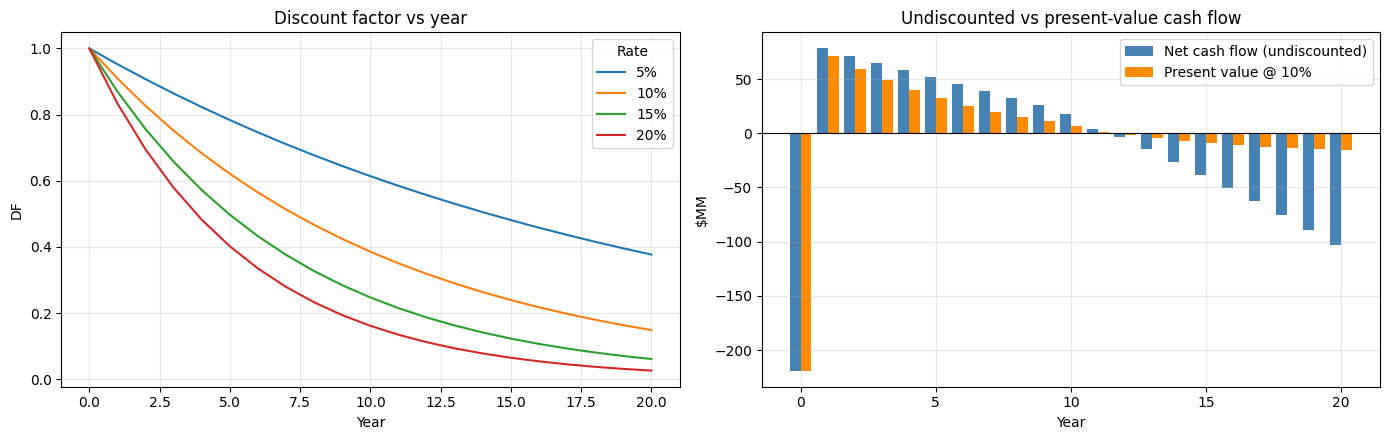

In [5]:
def discount_factor(rate, t):
    '''Discount factor 1/(1+i)^t.  `t` can be a scalar or an array of years.'''
    return 1.0 / (1.0 + rate) ** np.asarray(t, dtype=float)


def present_value(cash_flow, rate, t):
    '''Present value of cash flow(s) received at time(s) t.'''
    return np.asarray(cash_flow, dtype=float) * discount_factor(rate, t)


# (a) the concept in one line: what is $100 MM received in year 5 worth today?
print(f"$100 MM received in year 5, discounted at {DISC:.0%}:")
print(f"   discount factor = {float(discount_factor(DISC, 5)):.4f}   ->   present value = {float(present_value(100, DISC, 5)):.2f} $MM")
print(f"   (equivalently, $100 MM today grows to {100 * (1 + DISC) ** 5:.2f} $MM in 5 years)\n")

# (b) discount factors at several rates
rates_demo = [0.05, 0.10, 0.15, 0.20]
df_table = pd.DataFrame({"Year": base_cf["Year"]})
for r in rates_demo:
    df_table[f"DF @ {r:.0%}"] = discount_factor(r, base_cf["Year"])
print("Discount-factor table:")
display(df_table.round(4))

# (c) present value of the project's net cash flow at the project discount rate
pv_table = base_cf[["Year", "NCF"]].copy()
pv_table["DF"] = discount_factor(DISC, pv_table["Year"])
pv_table["PV"] = present_value(pv_table["NCF"], DISC, pv_table["Year"])
pv_table["Cum_PV"] = pv_table["PV"].cumsum()
print(f"\nPresent value of the net cash flow at {DISC:.0%}:")
display(pv_table.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for r in rates_demo:
    ax[0].plot(base_cf["Year"], discount_factor(r, base_cf["Year"]), label=f"{r:.0%}")
ax[0].set(title="Discount factor vs year", xlabel="Year", ylabel="DF"); ax[0].legend(title="Rate")
w = 0.4
ax[1].bar(pv_table["Year"] - w / 2, pv_table["NCF"], w, label="Net cash flow (undiscounted)", color="steelblue")
ax[1].bar(pv_table["Year"] + w / 2, pv_table["PV"], w, label=f"Present value @ {DISC:.0%}", color="darkorange")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(title="Undiscounted vs present-value cash flow", xlabel="Year", ylabel="$MM"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Net Present Value (NPV)
$$NPV = \sum_{t=0}^{N} \frac{NCF_t}{(1+i)^t}$$
NPV is the value created **in today's dollars** after recovering the investment and earning the required return *i*. Decision rule: **NPV > 0 → accept**; for mutually exclusive projects, the highest NPV creates the most value (when capital is not limiting).

NPV of the Base case @ 10% = 24.314 $MM   -> ACCEPT (creates value)



,$MM
PV of revenue (+),"1,025.133"
PV of CAPEX (-),-219.000
PV of OPEX (-),-649.363
PV of tax (-),-132.456
NPV,24.314


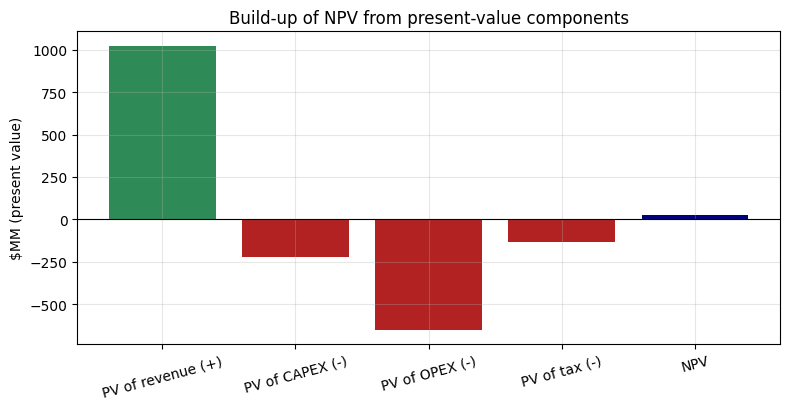

In [6]:
def npv(cash_flow, rate, t=None):
    '''Net present value.  t = time of each cash flow (defaults to 0,1,2,...).'''
    cash_flow = np.asarray(cash_flow, dtype=float)
    t = np.arange(len(cash_flow)) if t is None else t
    return float(present_value(cash_flow, rate, t).sum())


NPV_base = npv(base_cf["NCF"], DISC, base_cf["Year"])

# where does the NPV come from?  (present value of every cash-flow component)
DFs = discount_factor(DISC, base_cf["Year"])
components = pd.Series({
    "PV of revenue (+)": (base_cf["Revenue"] * DFs).sum(),
    "PV of CAPEX (-)":   -(base_cf["CAPEX"] * DFs).sum(),
    "PV of OPEX (-)":    -(base_cf["OPEX"] * DFs).sum(),
    "PV of tax (-)":     -(base_cf["Tax"] * DFs).sum(),
})
components["NPV"] = components.sum()
print(f"NPV of the {base_inputs.name} case @ {DISC:.0%} = {NPV_base:,.3f} $MM   "
      f"-> {'ACCEPT (creates value)' if NPV_base > 0 else 'REJECT (destroys value)'}\n")
display(components.to_frame("$MM"))
assert abs(components["NPV"] - NPV_base) < 1e-9

fig, ax = plt.subplots(figsize=(8, 4.2))
vals = components.values
ax.bar(components.index, vals, color=["seagreen", "firebrick", "firebrick", "firebrick", "navy"])
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("$MM (present value)")
ax.set_title("Build-up of NPV from present-value components"); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

## 7. Internal Rate of Return (IRR) — with multiple-IRR detection and MIRR
The IRR is the discount rate that makes NPV = 0:

$$0 = \sum_{t=0}^{N} \frac{NCF_t}{(1+IRR)^t}$$

Rule for a *conventional* cash flow (one sign change: −, +, +, …): **accept if IRR > discount rate**.

**Caution.** If the cash flow changes sign more than once (for example late-life costs exceeding revenue with no abandonment) the NPV equation can have **several roots**, and Excel's `IRR()` simply returns one of them. The algorithm therefore:

1. counts sign changes (Descartes' rule gives the maximum number of positive roots),
2. finds **all** real IRR roots,
3. also computes the **MIRR** (modified IRR, financing and reinvesting at the discount rate), which is always unique.

Sign changes in the net cash flow : 2
IRR root(s)                       : 6.26% | 21.19%
MIRR (finance = reinvest = 10%)  : 10.42%

>> MULTIPLE IRRs: the cash flow turns negative again late in life, so the IRR test is ambiguous.
   NPV > 0 exactly for discount rates BETWEEN the roots; use NPV (and MIRR) for the decision, not a single IRR.


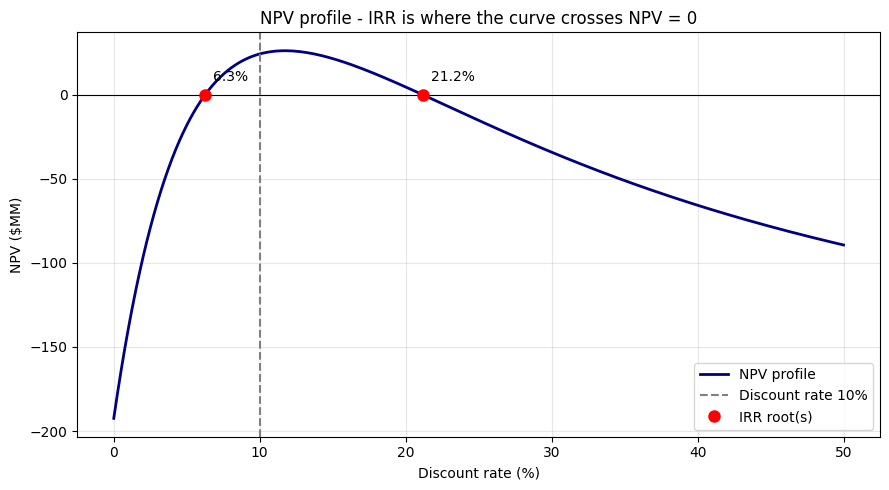

In [7]:
def sign_changes(cash_flow):
    '''Number of sign changes in the cash-flow sequence (upper bound on the number of IRR roots).'''
    s = np.sign(np.asarray(cash_flow, float))
    s = s[s != 0]
    return int((s[1:] != s[:-1]).sum())


def irr_roots(cash_flow):
    '''All real IRR roots > -99 % of a cash-flow series (root finding on the NPV polynomial).
    With x = 1/(1+IRR):  sum(CF_t * x^t) = 0.  np.roots finds every root, Newton polishing refines them.'''
    cf = np.asarray(cash_flow, dtype=float)
    nz = np.nonzero(cf)[0]
    if len(nz) < 2:
        return []
    cf = cf[nz[0]:nz[-1] + 1]                      # leading/trailing zeros do not change the IRR
    if not (cf.min() < 0 < cf.max()):
        return []                                  # no sign change -> no IRR
    t = np.arange(len(cf))
    roots = []
    for z in np.roots(cf[::-1]):                   # np.roots expects highest power first
        if abs(z.imag) > 1e-6 * max(1.0, abs(z)) or z.real <= 0:
            continue
        r = 1.0 / z.real - 1.0
        if r <= -0.99:
            continue
        for _ in range(50):                        # Newton polish on f(r) = sum CF/(1+r)^t
            f = (cf / (1 + r) ** t).sum()
            fp = (-t * cf / (1 + r) ** (t + 1)).sum()
            if fp == 0:
                break
            step = f / fp
            r -= step
            if abs(step) < 1e-13:
                break
        if abs((cf / (1 + r) ** t).sum()) < 1e-6 * max(1.0, np.abs(cf).max()):
            if all(abs(r - x) > 1e-7 for x in roots):
                roots.append(float(r))
    return sorted(roots)


def mirr(cash_flow, rate):
    '''Modified IRR: negative flows discounted to t=0 and positive flows compounded to the end, both at `rate`.'''
    cf = np.asarray(cash_flow, dtype=float)
    nz = np.nonzero(cf)[0]
    if len(nz) < 2:
        return float("nan")
    cf = cf[nz[0]:nz[-1] + 1]
    n, t = len(cf) - 1, np.arange(len(cf))
    fv_pos = (np.where(cf > 0, cf, 0.0) * (1 + rate) ** (n - t)).sum()
    pv_neg = -(np.where(cf < 0, cf, 0.0) / (1 + rate) ** t).sum()
    return float((fv_pos / pv_neg) ** (1.0 / n) - 1.0) if fv_pos > 0 and pv_neg > 0 else float("nan")


def fmt_roots(roots):
    return " | ".join(f"{r:.2%}" for r in roots) if roots else "none"


ncf_base = base_cf["NCF"].values
roots_base = irr_roots(ncf_base)
mirr_base = mirr(ncf_base, DISC)
print(f"Sign changes in the net cash flow : {sign_changes(ncf_base)}")
print(f"IRR root(s)                       : {fmt_roots(roots_base)}")
print(f"MIRR (finance = reinvest = {DISC:.0%})  : {mirr_base:.2%}")
if len(roots_base) > 1:
    print("\n>> MULTIPLE IRRs: the cash flow turns negative again late in life, so the IRR test is ambiguous.")
    print("   NPV > 0 exactly for discount rates BETWEEN the roots; use NPV (and MIRR) for the decision, not a single IRR.")

# NPV profile: NPV as a function of the discount rate; the IRR roots are where the curve crosses zero
rate_grid = np.linspace(0.0, CONFIG["NPV_PROFILE_MAX_RATE"], 201)
profile = [npv(ncf_base, r, base_cf["Year"]) for r in rate_grid]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rate_grid * 100, profile, color="navy", lw=2, label="NPV profile")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(DISC * 100, color="gray", ls="--", label=f"Discount rate {DISC:.0%}")
for k, r in enumerate(roots_base):
    ax.plot(r * 100, 0, "ro", ms=8, label="IRR root(s)" if k == 0 else None)
    ax.annotate(f"{r:.1%}", (r * 100, 0), textcoords="offset points", xytext=(6, 10))
ax.set(title="NPV profile - IRR is where the curve crosses NPV = 0", xlabel="Discount rate (%)", ylabel="NPV ($MM)")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Payback period (payout)
* **Simple payback**: time for the cumulative *undiscounted* net cash flow to turn positive (linear interpolation inside the crossing year: `t + |cum_t| / NCF_(t+1)`, identical to the workbook formula).
* **Discounted payback**: same, on the cumulative *discounted* cash flow — stricter because it charges the cost of money.

Payback measures capital-recovery speed and risk exposure; it ignores everything that happens after recovery.

Simple payback     : 3.07 years
Discounted payback : 4.00 years   (at 10%)


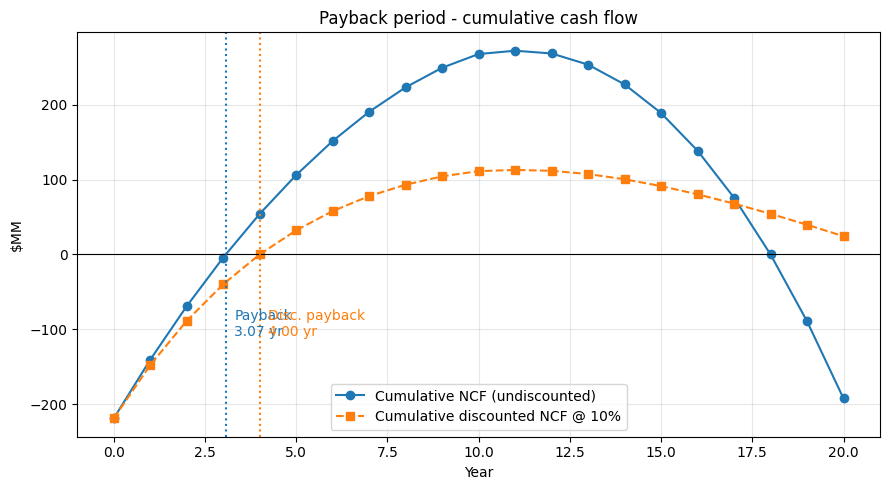

In [8]:
def payback_period(cash_flow, times=None):
    '''Years until cumulative cash flow first changes from negative to non-negative (interpolated).
    Returns None if the investment is never recovered.'''
    cf = np.asarray(cash_flow, dtype=float)
    times = np.arange(len(cf)) if times is None else np.asarray(times, dtype=float)
    cum = np.cumsum(cf)
    for i in range(len(cf) - 1):
        if cum[i] < 0 <= cum[i + 1]:
            return float(times[i] + (-cum[i]) / cf[i + 1] * (times[i + 1] - times[i]))
    return None


def discounted_payback_period(cash_flow, rate, times=None):
    cf = np.asarray(cash_flow, dtype=float)
    times = np.arange(len(cf)) if times is None else np.asarray(times, dtype=float)
    return payback_period(present_value(cf, rate, times), times)


pb_base = payback_period(ncf_base, base_cf["Year"])
dpb_base = discounted_payback_period(ncf_base, DISC, base_cf["Year"])
f = lambda x: "never" if x is None else f"{x:.2f} years"
print(f"Simple payback     : {f(pb_base)}")
print(f"Discounted payback : {f(dpb_base)}   (at {DISC:.0%})")

cum_nc = np.cumsum(ncf_base)
cum_pv = np.cumsum(present_value(ncf_base, DISC, base_cf["Year"]))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(base_cf["Year"], cum_nc, "o-", label="Cumulative NCF (undiscounted)")
ax.plot(base_cf["Year"], cum_pv, "s--", label=f"Cumulative discounted NCF @ {DISC:.0%}")
ax.axhline(0, color="k", lw=0.8)
for val, lab, c in ((pb_base, "Payback", "C0"), (dpb_base, "Disc. payback", "C1")):
    if val is not None:
        ax.axvline(val, color=c, ls=":"); ax.annotate(f"{lab}\n{val:.2f} yr", (val, cum_nc.min() * 0.5),
                                                     textcoords="offset points", xytext=(6, 0), color=c)
ax.set(title="Payback period - cumulative cash flow", xlabel="Year", ylabel="$MM"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Profit / investment ratio (profitability index)
Value created per dollar invested, measured in present-value terms:

$$PI = \frac{PV\ \text{of net inflows (revenue - opex - tax)}}{PV\ \text{of investment}} \qquad PIR = \frac{NPV}{PV\ \text{of investment}} = PI - 1$$

* **PIR > 0 (PI > 1)** → the project earns more than the required return.
* The template's *Capital Productivity Index (CPI)* is `NPV / CAPEX`; it equals the PIR when the whole investment is spent at year 0.
* The **undiscounted** ratio (total net profit / total investment) is also reported for completeness.
* PI/PIR is the right ranking measure when **capital is rationed**, because it measures capital efficiency, not size.

In [9]:
def profitability(cf, rate):
    '''Profitability measures of a cash-flow table (needs columns Year, CAPEX, Revenue, OPEX, Tax, NCF).'''
    dfs = discount_factor(rate, cf["Year"])
    pv_capex = float((cf["CAPEX"] * dfs).sum())
    pv_net_inflow = float(((cf["Revenue"] - cf["OPEX"] - cf["Tax"]) * dfs).sum())
    npv_ = pv_net_inflow - pv_capex
    return {"PV_Capex": pv_capex, "PV_NetInflow": pv_net_inflow,
            "PI": pv_net_inflow / pv_capex, "PIR": npv_ / pv_capex,
            "PIR_undiscounted": float(cf["NCF"].sum() / cf["CAPEX"].sum())}


prof_base = profitability(base_cf, DISC)
print(f"PV of net inflows      : {prof_base['PV_NetInflow']:,.2f} $MM")
print(f"PV of investment       : {prof_base['PV_Capex']:,.2f} $MM")
print(f"Profitability index PI : {prof_base['PI']:.3f}    (PI > 1 is acceptable)")
print(f"Profit/investment PIR  : {prof_base['PIR']:.3f}    (= NPV / PV investment = template CPI)")
print(f"Undiscounted PIR       : {prof_base['PIR_undiscounted']:.3f}    (total net profit / total investment)")

PV of net inflows      : 243.31 $MM
PV of investment       : 219.00 $MM
Profitability index PI : 1.111    (PI > 1 is acceptable)
Profit/investment PIR  : 0.111    (= NPV / PV investment = template CPI)
Undiscounted PIR       : -0.879    (total net profit / total investment)


## 10. All indicators together, screening, and verification
`evaluate()` is the single routine used from here on: it turns any cash-flow table into the full set of indicators. Screening uses the rules (NPV > 0; IRR vs discount rate; payback < limit; CPI > 0), with the IRR test made robust to multiple roots.

In [10]:
def evaluate(cf, rate):
    '''Full indicator set for one cash-flow table.
    NPV/PI are discounted to today (column Year); IRR, MIRR and payback are measured from the investment date (ProjYear >= 0).'''
    proj = cf["ProjYear"].values
    on = proj >= 0
    ncf, yr = cf["NCF"].values, cf["Year"].values
    ncf_p, t_p = ncf[on], proj[on].astype(float)
    m = {"Capex": float(cf["CAPEX"].sum()),
         "NPV": npv(ncf, rate, yr),
         "IRR_roots": irr_roots(ncf_p),
         "MIRR": mirr(ncf_p, rate),
         "Payback": payback_period(ncf_p, t_p),
         "Disc_Payback": discounted_payback_period(ncf_p, rate, t_p),
         "Sign_Changes": sign_changes(ncf_p)}
    m.update(profitability(cf, rate))
    m["N_IRR"] = len(m["IRR_roots"])
    m["IRR_text"] = fmt_roots(m["IRR_roots"])
    m["IRR_low"] = m["IRR_roots"][0] if m["IRR_roots"] else float("nan")
    m["IRR_high"] = m["IRR_roots"][-1] if m["IRR_roots"] else float("nan")
    m["Last_Producing_Year"] = int(cf.loc[cf["Revenue"] > 0, "ProjYear"].max()) if (cf["Revenue"] > 0).any() else 0
    return m


def screening_table(m, rate, cfg=None):
    '''Accept / reject checks in the same spirit as the template's OK / Not OK column.'''
    cfg = cfg or CONFIG
    if m["N_IRR"] == 1:
        irr_val, irr_ok = f"{m['IRR_low']:.2%}", m["IRR_low"] > rate
        irr_crit = f"IRR > {rate:.0%}"
    elif m["N_IRR"] == 0:
        irr_val, irr_ok, irr_crit = "no IRR", False, "cash flow has no sign change"
    else:
        irr_val = m["IRR_text"]
        irr_ok = (m["NPV"] > 0) and (m["MIRR"] > rate)
        irr_crit = f"multiple IRRs -> NPV > 0 and MIRR ({m['MIRR']:.2%}) > {rate:.0%}"
    pb_ok = m["Payback"] is not None and m["Payback"] < cfg["PAYBACK_LIMIT_YEARS"]
    rows = [("NPV ($MM)", f"{m['NPV']:,.3f}", "NPV > 0", m["NPV"] > 0),
            ("IRR", irr_val, irr_crit, irr_ok),
            ("Payback (years)", "never" if m["Payback"] is None else f"{m['Payback']:.2f}",
             f"< {cfg['PAYBACK_LIMIT_YEARS']} years", pb_ok),
            ("Discounted payback (years)", "never" if m["Disc_Payback"] is None else f"{m['Disc_Payback']:.2f}",
             "recovered within project life", m["Disc_Payback"] is not None),
            ("Profitability index PI", f"{m['PI']:.3f}", "PI > 1", m["PI"] > 1),
            ("Profit/investment ratio PIR (= CPI)", f"{m['PIR']:.3f}", "PIR > 0", m["PIR"] > 0)]
    return pd.DataFrame(rows, columns=["Indicator", "Value", "Criterion", "OK?"]).assign(
        **{"OK?": lambda d: np.where(d["OK?"], "OK", "Not OK")})


base_metrics = evaluate(base_cf, DISC)
print(f"=== Economic indicators: {base_inputs.name} case @ {DISC:.0%} ===")
display(screening_table(base_metrics, DISC))
print(f"MIRR = {base_metrics['MIRR']:.2%}   |   undiscounted PIR = {base_metrics['PIR_undiscounted']:.3f}   |   "
      f"last producing year = {base_metrics['Last_Producing_Year']}")

# ---- verification: does this Python model reproduce the numbers stored in the Excel workbook? ----
tr = base_inputs.template_results
if tr:
    lowest = base_metrics["IRR_roots"][0] if base_metrics["IRR_roots"] else float("nan")
    closest_root = min(base_metrics["IRR_roots"], key=lambda r: abs(r - tr["IRR"])) if base_metrics["IRR_roots"] and "IRR" in tr else float("nan")
    checks = [("NPV ($MM)", base_metrics["NPV"], tr.get("NPV")),
              ("IRR (matching root)", closest_root, tr.get("IRR")),
              ("Payback (years)", base_metrics["Payback"], tr.get("Payback")),
              ("CPI = NPV/CAPEX", base_metrics["Capex"] and base_metrics["NPV"] / base_metrics["Capex"], tr.get("CPI"))]
    ver = pd.DataFrame([(n, py, xl, (py - xl) if (py is not None and xl is not None) else np.nan) for n, py, xl in checks],
                       columns=["Indicator", "Python", "Workbook", "Difference"])
    ver["Match"] = np.where(ver["Difference"].abs() < 1e-6, "YES", "NO")
    print("\nVerification against the results stored in your workbook:")
    display(ver)
    if any(CONFIG[k] for k in ("APPLY_PRICE_ESCALATION", "ECONOMIC_LIMIT_CUTOFF", "LOSS_CARRY_FORWARD")):
        print("Note: a CONFIG switch differs from the workbook logic, so differences are expected.")
    if len(base_metrics["IRR_roots"]) > 1:
        print(f"\nNote: the workbook's IRR ({tr['IRR']:.2%}) is only ONE of the roots ({fmt_roots(base_metrics['IRR_roots'])}). "
              "The workbook's 'Not OK' IRR verdict comes from that single root; here the multiple-IRR-aware test is used.")
else:
    print("\n(No results stored in the workbook to verify against.)")

=== Economic indicators: Base case @ 10% ===


,Indicator,Value,Criterion,OK?
0,NPV ($MM),24.314,NPV > 0,OK
1,IRR,6.26% | 21.19%,multiple IRRs -> NPV > 0 and MIRR (10.42%) > 10%,OK
2,Payback (years),3.07,< 10 years,OK
3,Discounted payback (years),4.00,recovered within project life,OK
4,Profitability index PI,1.111,PI > 1,OK
5,Profit/investment ratio PIR (= CPI),0.111,PIR > 0,OK


MIRR = 10.42%   |   undiscounted PIR = -0.879   |   last producing year = 20

Verification against the results stored in your workbook:


,Indicator,Python,Workbook,Difference,Match
0,NPV ($MM),24.314,24.314,-0.000,YES
1,IRR (matching root),0.063,0.063,-0.000,YES
2,Payback (years),3.072,3.072,0.000,YES
3,CPI = NPV/CAPEX,0.111,0.111,-0.000,YES



Note: the workbook's IRR (6.26%) is only ONE of the roots (6.26% | 21.19%). The workbook's 'Not OK' IRR verdict comes from that single root; here the multiple-IRR-aware test is used.


## 11. Diagnostic: fixed project life vs. economic-limit abandonment
The template fixes the life at 20 years with no abandonment. When operating cost (inflating at 1–10 %/yr) overtakes revenue, keeping the field on stream produces **negative cash flows in the tail**; that is what creates multiple IRRs above. A real operator would shut the field in at its **economic limit**. This table shows how much the assumption matters (it does *not* change the main analysis unless you set `CONFIG["ECONOMIC_LIMIT_CUTOFF"] = True`).

In [11]:
cfg_fixed = {**CONFIG, "ECONOMIC_LIMIT_CUTOFF": False}
cfg_limit = {**CONFIG, "ECONOMIC_LIMIT_CUTOFF": True}
life_rows = {}
for label, c in (("Fixed life (template)", cfg_fixed), ("Abandon at economic limit", cfg_limit)):
    cf_ = build_cash_flow(base_inputs, cfg=c)
    m_ = evaluate(cf_, DISC)
    life_rows[label] = {"Last producing year": m_["Last_Producing_Year"], "NPV ($MM)": m_["NPV"],
                        "IRR root(s)": m_["IRR_text"], "MIRR": f"{m_['MIRR']:.2%}",
                        "Payback (yr)": m_["Payback"], "PIR": m_["PIR"], "Undiscounted profit ($MM)": cf_["NCF"].sum()}
life_table = pd.DataFrame(life_rows).T
display(life_table)
gain = life_rows["Abandon at economic limit"]["NPV ($MM)"] - life_rows["Fixed life (template)"]["NPV ($MM)"]
print(f"Abandoning at the economic limit changes NPV by {gain:+,.1f} $MM and leaves a single, unambiguous IRR."
      if gain > 0 else "Abandonment at the economic limit does not improve NPV for this dataset.")

,Last producing year,NPV ($MM),IRR root(s),MIRR,Payback (yr),PIR,Undiscounted profit ($MM)
Fixed life (template),20,24.314,6.26% | 21.19%,10.42%,3.072,0.111,-192.446
Abandon at economic limit,11,112.855,24.09%,14.24%,3.072,0.515,272.130


Abandoning at the economic limit changes NPV by +88.5 $MM and leaves a single, unambiguous IRR.


## 12. Effect of the start-up date
Delaying first production pushes every cash flow further out on the discounting timeline. Even if the project itself is unchanged, a later start-up:
* discounts the same net cash flows more heavily → **lower NPV**,
* pushes payback further from today (in calendar time) — though the *project-clock* payback is unchanged unless costs escalate while waiting,
* leaves IRR/PI almost unchanged (they are measured from the investment date), unless costs escalate while waiting.

`CONFIG["STARTUP_DELAYS"]` sets the delays tested (years); `CONFIG["INFLATE_DURING_DELAY"]` controls whether opex keeps inflating while the project waits; `CONFIG["CAPEX_ESCALATION"]` lets you add capex cost-escalation per year of delay.

Effect of start-up delay on the economic indicators:


,NPV ($MM),IRR,MIRR,Payback from today (yr),Payback from start-up (yr),PIR
Delay (years),,,,,,
0,24.314,6.26% | 21.19%,0.104,3.072,3.072,0.111
1,-9.286,none,0.098,4.182,3.182,-0.047
2,-40.199,none,0.092,5.312,3.312,-0.222
3,-67.845,none,0.085,6.464,3.464,-0.412
4,-92.738,none,0.077,7.645,3.645,-0.620
5,-114.767,none,0.069,8.864,3.864,-0.844



Each year of delay costs about 27.82 $MM of NPV on average (24.3 $MM at t=0 vs -114.8 $MM at 5-year delay).


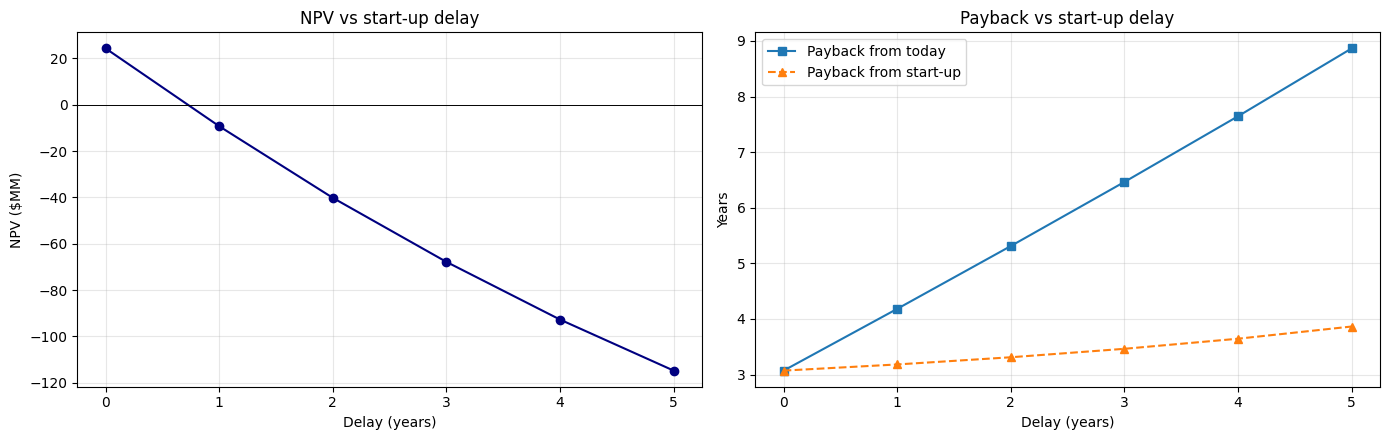

In [12]:
startup_rows = []
startup_cfs = {}
for delay in CONFIG["STARTUP_DELAYS"]:
    cf_d = build_cash_flow(base_inputs, startup_delay=delay)
    m_d = evaluate(cf_d, DISC)
    startup_cfs[delay] = cf_d
    startup_rows.append({"Delay (years)": delay, "NPV ($MM)": m_d["NPV"], "IRR": m_d["IRR_text"],
                         "MIRR": m_d["MIRR"], "Payback from today (yr)": (m_d["Payback"] + delay) if m_d["Payback"] is not None else None,
                         "Payback from start-up (yr)": m_d["Payback"], "PIR": m_d["PIR"]})
startup_df = pd.DataFrame(startup_rows).set_index("Delay (years)")
print("Effect of start-up delay on the economic indicators:")
display(startup_df.round(3))

npv0 = startup_df.loc[0, "NPV ($MM)"]
per_year = (startup_df.loc[startup_df.index.max(), "NPV ($MM)"] - npv0) / startup_df.index.max()
print(f"\nEach year of delay costs about {-per_year:.2f} $MM of NPV on average "
      f"({npv0:.1f} $MM at t=0 vs {startup_df.iloc[-1]['NPV ($MM)']:.1f} $MM at "
      f"{startup_df.index.max()}-year delay).")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(startup_df.index, startup_df["NPV ($MM)"], "o-", color="navy")
ax[0].axhline(0, color="k", lw=0.7)
ax[0].set(title="NPV vs start-up delay", xlabel="Delay (years)", ylabel="NPV ($MM)")
ax[1].plot(startup_df.index, startup_df["Payback from today (yr)"], "s-", label="Payback from today")
ax[1].plot(startup_df.index, startup_df["Payback from start-up (yr)"], "^--", label="Payback from start-up")
ax[1].set(title="Payback vs start-up delay", xlabel="Delay (years)", ylabel="Years"); ax[1].legend()
plt.tight_layout(); plt.show()

## 13. Development alternatives (mutually exclusive projects)
The template describes a single development plan. To compare alternatives, this section builds a family of **mutually exclusive** development sizes by scaling the number of wells; production scales sub-proportionally (`wells^RESERVOIR_RESPONSE_EXPONENT`, well-interference/diminishing-returns) and facilities/camp/pipeline/fixed-opex scale with the six-tenths rule (`size^FACILITY_SCALING_EXPONENT`). Well-count-linked items (drilling, well services) scale linearly. The template case itself (scale = 1.0) is always included.

You can bypass the scaling and hand-enter your own alternatives in `CONFIG["CUSTOM_ALTERNATIVES"]`.

Development alternatives (ranked by NPV, highest first):


,Wells,Capex ($MM),NPV ($MM),IRR,MIRR,Payback (yr),PI,PIR
Alternative,,,,,,,,
1.2x wells (36 wells),36.000,256.976,24.422,6.65% | 20.69%,0.104,3.095,1.095,0.095
Base (template),30.000,219.000,24.314,6.26% | 21.19%,0.104,3.072,1.111,0.111
0.8x wells (24 wells),24.000,180.354,23.492,5.79% | 21.71%,0.105,3.048,1.130,0.130
1.5x wells (45 wells),45.000,313.004,20.948,7.44% | 19.77%,0.103,3.134,1.067,0.067
0.6x wells (18 wells),18.000,140.786,20.245,5.47% | 22.06%,0.105,3.032,1.144,0.144
2.0x wells (60 wells),60.000,404.584,10.431,8.83% | 18.15%,0.101,3.197,1.026,0.026


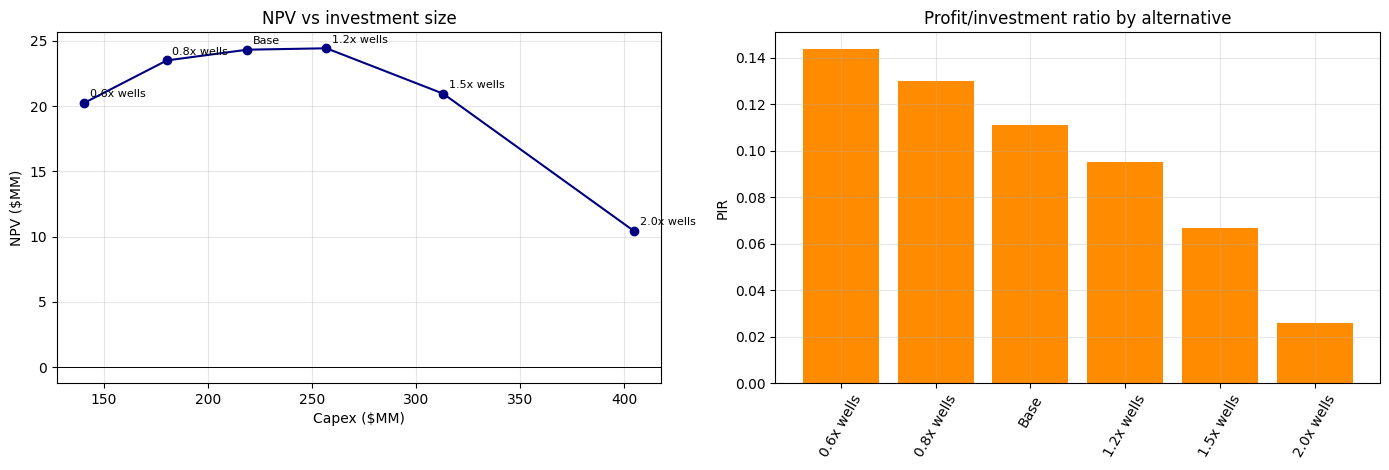

In [13]:
def make_alternative(base, scale, label=None):
    '''Return a ProjectInputs for a development scaled to `scale` x the base number of wells.'''
    wells = max(1, round(base.wells * scale))
    sw = wells / base.wells                          # actual well-count ratio (after rounding)
    sf = sw ** CONFIG["FACILITY_SCALING_EXPONENT"]    # six-tenths-rule scaling for facilities/fixed items
    sq = sw ** CONFIG["RESERVOIR_RESPONSE_EXPONENT"]  # sub-proportional production response
    alt = replace(base, name=label or f"{scale:.1f}x wells", wells=wells, q1_mbd=base.q1_mbd * sq,
                 facilities=base.facilities * sf, camp=base.camp * sf, pipe_unit_cost=base.pipe_unit_cost * sf,
                 fuel=base.fuel * sf, spares=base.spares * sf, maint=base.maint * sf,
                 overhead=base.overhead * sf, personnel=max(1, round(base.personnel * sf)))
    return alt


def build_alternatives(base):
    alts = {}
    if CONFIG["CUSTOM_ALTERNATIVES"]:
        for label, overrides in CONFIG["CUSTOM_ALTERNATIVES"].items():
            alts[label] = replace(base, name=label, **overrides)
        alts.setdefault(f"{base.name} (template)", base)
    else:
        for s in CONFIG["DEVELOPMENT_SCALES"]:
            label = f"{base.name} (template)" if abs(s - 1.0) < 1e-9 else f"{s:.1f}x wells ({round(base.wells * s)} wells)"
            alts[label] = base if abs(s - 1.0) < 1e-9 else make_alternative(base, s, label)
    return alts


alternatives = build_alternatives(base_inputs)
alt_cf = {label: build_cash_flow(p) for label, p in alternatives.items()}
alt_metrics = {label: evaluate(cf, DISC) for label, cf in alt_cf.items()}

summary_rows = []
for label, m in alt_metrics.items():
    summary_rows.append({"Alternative": label, "Wells": alternatives[label].wells, "Capex ($MM)": m["Capex"],
                         "NPV ($MM)": m["NPV"], "IRR": m["IRR_text"], "MIRR": m["MIRR"],
                         "Payback (yr)": m["Payback"], "PI": m["PI"], "PIR": m["PIR"]})
summary_df = pd.DataFrame(summary_rows).set_index("Alternative")
if CONFIG["CAPITAL_BUDGET"] is not None:
    within = summary_df["Capex ($MM)"] <= CONFIG["CAPITAL_BUDGET"]
    print(f"Capital budget = {CONFIG['CAPITAL_BUDGET']} $MM -> "
         f"{within.sum()}/{len(within)} alternatives affordable (flagged 'x' below).")
    summary_df.insert(0, "Within budget", np.where(within, "", "x"))
print("Development alternatives (ranked by NPV, highest first):")
display(summary_df.sort_values("NPV ($MM)", ascending=False).round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
order = summary_df.sort_values("Capex ($MM)")
ax[0].plot(order["Capex ($MM)"], order["NPV ($MM)"], "o-", color="navy")
short_label = lambda s: s.split(" (")[0]
for lbl, row in order.iterrows():
    ax[0].annotate(short_label(lbl), (row["Capex ($MM)"], row["NPV ($MM)"]), fontsize=8,
                   textcoords="offset points", xytext=(4, 4))
ax[0].axhline(0, color="k", lw=0.7); ax[0].set(title="NPV vs investment size", xlabel="Capex ($MM)", ylabel="NPV ($MM)")
ax[1].bar([short_label(l) for l in order.index], order["PIR"], color="darkorange")
ax[1].set(title="Profit/investment ratio by alternative", ylabel="PIR"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 14. Incremental analysis between mutually exclusive alternatives
Ranking alternatives by NPV picks the value-maximising option automatically, but it can **hide a poor return on the extra capital** spent to get there. Incremental analysis answers: *is the extra investment, by itself, worth it?*

Sorted by increasing capex, each step is compared with the previous (surviving) alternative:

$$\Delta NCF_t = NCF_t^{(bigger)} - NCF_t^{(smaller)} \qquad \Delta NPV,\ \Delta IRR,\ \Delta PIR \text{ computed on } \Delta NCF$$

Decision rule: accept the increment (move up to the bigger project) only if **ΔNPV > 0** (equivalently ΔIRR > discount rate). Applying this test step-by-step, from the smallest affordable alternative upward, finds the same NPV-maximising project as Section 13 — but shows *why*, one incremental dollar at a time.

In [14]:
def incremental_chain(cf_dict, rate, order):
    '''Walk `order` (small -> large capex) and test each increment against the current best.'''
    rows, current = [], order[0]
    for nxt in order[1:]:
        a, b = cf_dict[current], cf_dict[nxt]
        n = max(len(a), len(b))
        d_ncf = np.zeros(n)
        d_ncf[:len(b)] += b["NCF"].values
        d_ncf[:len(a)] -= a["NCF"].values
        d_year = np.arange(n)
        d_capex = float(b["CAPEX"].sum() - a["CAPEX"].sum())
        d_npv = npv(d_ncf, rate, d_year)
        d_roots = irr_roots(d_ncf)
        d_mirr = mirr(d_ncf, rate)
        accept = d_npv > 0
        rows.append({"Increment": f"{current}  ->  {nxt}", "Delta Capex ($MM)": d_capex,
                     "Delta NPV ($MM)": d_npv, "Delta IRR": fmt_roots(d_roots), "Delta MIRR": d_mirr,
                     "Delta PIR": d_npv / d_capex if d_capex else float("nan"),
                     "Decision": "TAKE increment (move up)" if accept else "STOP (stay with smaller)"})
        if accept:
            current = nxt                                # keep climbing only while value is created
    return pd.DataFrame(rows), current


order_by_capex = summary_df["Capex ($MM)"].sort_values().index.tolist()
if CONFIG["CAPITAL_BUDGET"] is not None:
    order_by_capex = [a for a in order_by_capex if summary_df.loc[a, "Capex ($MM)"] <= CONFIG["CAPITAL_BUDGET"]]
inc_table, inc_winner = incremental_chain(alt_cf, DISC, order_by_capex)
print("Incremental (Delta) analysis, walking from the smallest to the largest development:")
display(inc_table.round(3))
print(f"\nIncremental analysis selects : {inc_winner}")
print(f"Highest stand-alone NPV      : {summary_df['NPV ($MM)'].idxmax()}")
print("-> " + ("The two methods agree." if inc_winner == summary_df['NPV ($MM)'].idxmax()
               else "They disagree: this only happens when a capital budget removes the NPV-maximising option from the chain."))

Incremental (Delta) analysis, walking from the smallest to the largest development:


,Increment,Delta Capex ($MM),Delta NPV ($MM),Delta IRR,Delta MIRR,Delta PIR,Decision
0,0.6x wells (18 wells) -> 0.8x wells (24 wells),39.568,3.247,7.03% | 20.35%,0.103,0.082,TAKE increment (move up)
1,0.8x wells (24 wells) -> Base (template),38.646,0.822,9.03% | 18.14%,0.101,0.021,TAKE increment (move up)
2,Base (template) -> 1.2x wells (36 wells),37.976,0.108,9.85% | 16.91%,0.100,0.003,TAKE increment (move up)
3,1.2x wells (36 wells) -> 1.5x wells (45 wells),56.028,-3.474,none,0.098,-0.062,STOP (stay with smaller)
4,1.2x wells (36 wells) -> 2.0x wells (60 wells),147.608,-13.991,none,0.096,-0.095,STOP (stay with smaller)



Incremental analysis selects : 1.2x wells (36 wells)
Highest stand-alone NPV      : 1.2x wells (36 wells)
-> The two methods agree.


## 15. Comparing all indicators and selecting the best development option
No single indicator tells the whole story:

| Indicator | Answers | Weakness used alone |
|---|---|---|
| NPV | How much value in $ | Favors bigger projects, hides capital efficiency |
| IRR / MIRR | Return on capital, % | Can be multiple/misleading with non-conventional cash flows |
| Payback | How fast capital is recovered | Ignores value created after payback |
| PI / PIR | Value per dollar invested | Ignores absolute project size |

The table below **ranks every alternative on each indicator** and combines the ranks (lower average rank = better across the board), then states the recommendation from each individual rule plus the overall pick. Where an unlimited-capital NPV ranking would disagree with a capital-constrained incremental ranking, both are shown.

=== Final comparison of all development alternatives ===


,Capex ($MM),NPV ($MM),IRR,MIRR,Payback (yr),PIR,NPV rank,MIRR rank,Payback rank,PIR rank,Average rank
Alternative,,,,,,,,,,,
0.6x wells (18 wells),140.786,20.245,5.47% | 22.06%,0.105,3.032,0.144,5.000,1.000,1.000,1.000,2.000
0.8x wells (24 wells),180.354,23.492,5.79% | 21.71%,0.105,3.048,0.130,3.000,2.000,2.000,2.000,2.250
Base (template),219.000,24.314,6.26% | 21.19%,0.104,3.072,0.111,2.000,3.000,3.000,3.000,2.750
1.2x wells (36 wells),256.976,24.422,6.65% | 20.69%,0.104,3.095,0.095,1.000,4.000,4.000,4.000,3.250
1.5x wells (45 wells),313.004,20.948,7.44% | 19.77%,0.103,3.134,0.067,4.000,5.000,5.000,5.000,4.750
2.0x wells (60 wells),404.584,10.431,8.83% | 18.15%,0.101,3.197,0.026,6.000,6.000,6.000,6.000,6.000



Best by NPV (unconstrained capital) : 1.2x wells (36 wells)  (24.42 $MM)
Best by PIR (capital efficiency)    : 0.6x wells (18 wells)  (PIR = 0.144)
Fastest payback                     : 0.6x wells (18 wells)  (3.03 yr)
Incremental (Delta-NPV) analysis winner   : 1.2x wells (36 wells)
Best overall (average rank)         : 0.6x wells (18 wells)

RECOMMENDATION: 1.2x wells (36 wells)
Capital is unconstrained -> take the NPV-maximising, incremental-analysis-confirmed development.


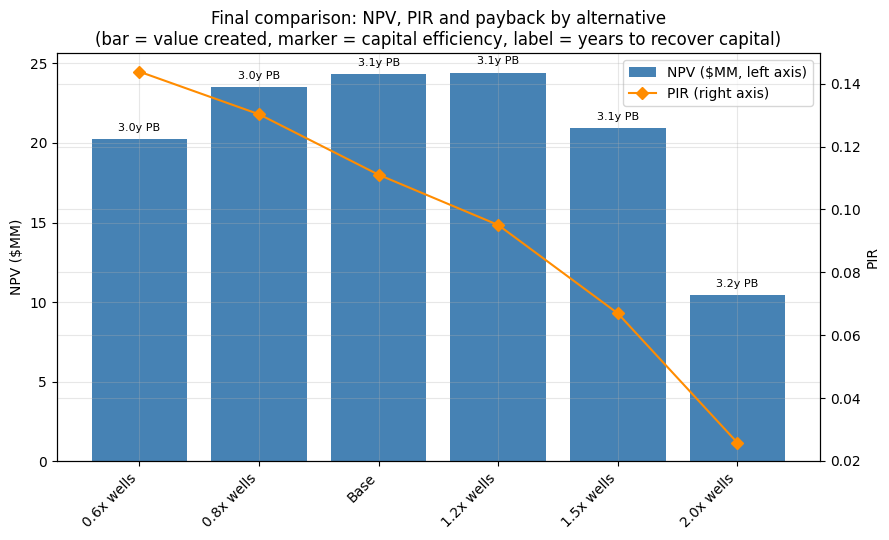

In [15]:
rank_df = pd.DataFrame({
    "NPV rank": summary_df["NPV ($MM)"].rank(ascending=False),
    "MIRR rank": summary_df["MIRR"].rank(ascending=False),
    "Payback rank": summary_df["Payback (yr)"].rank(ascending=True),
    "PIR rank": summary_df["PIR"].rank(ascending=False),
})
rank_df["Average rank"] = rank_df.mean(axis=1)
comparison = pd.concat([summary_df[["Capex ($MM)", "NPV ($MM)", "IRR", "MIRR", "Payback (yr)", "PIR"]],
                        rank_df], axis=1).sort_values("Average rank")
print("=== Final comparison of all development alternatives ===")
display(comparison.round(3))

best_npv = summary_df["NPV ($MM)"].idxmax()
best_pir = summary_df["PIR"].idxmax()
best_payback = summary_df["Payback (yr)"].idxmin()
best_overall = rank_df["Average rank"].idxmin()

print(f"\nBest by NPV (unconstrained capital) : {best_npv}  ({summary_df.loc[best_npv, 'NPV ($MM)']:.2f} $MM)")
print(f"Best by PIR (capital efficiency)    : {best_pir}  (PIR = {summary_df.loc[best_pir, 'PIR']:.3f})")
print(f"Fastest payback                     : {best_payback}  ({summary_df.loc[best_payback, 'Payback (yr)']:.2f} yr)")
print(f"Incremental (Delta-NPV) analysis winner   : {inc_winner}")
print(f"Best overall (average rank)         : {best_overall}")

recommendation = inc_winner if CONFIG["CAPITAL_BUDGET"] is not None else best_npv
print(f"\n{'='*78}\nRECOMMENDATION: {recommendation}")
print("Capital is unconstrained -> take the NPV-maximising, incremental-analysis-confirmed development."
     if CONFIG["CAPITAL_BUDGET"] is None else
     f"Capital budget = {CONFIG['CAPITAL_BUDGET']} $MM -> take the largest affordable increment that still adds value.")
print("="*78)

fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(comparison))
ax.bar(x, comparison["NPV ($MM)"], color="steelblue", label="NPV ($MM, left axis)")
ax.axhline(0, color="k", lw=0.7)
ax.set_xticks(x); ax.set_xticklabels([short_label(i) for i in comparison.index], rotation=45, ha="right")
ax.set_ylabel("NPV ($MM)")
ax2 = ax.twinx()
ax2.plot(x, comparison["PIR"], "D-", color="darkorange", label="PIR (right axis)")
ax2.set_ylabel("PIR")
for i in x:
    ax.annotate(f"{comparison['Payback (yr)'].iloc[i]:.1f}y PB", (i, comparison["NPV ($MM)"].iloc[i]),
               textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
lines1, labels1 = ax.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
ax.set_title("Final comparison: NPV, PIR and payback by alternative\n(bar = value created, marker = capital efficiency, label = years to recover capital)")
plt.tight_layout(); plt.show()

## 16. Sensitivity analysis (spider & tornado) on the recommended case
Using the **±ranges already in your template's sensitivity table**, each variable is flexed one at a time (all others held at base case) to see which assumption the NPV depends on most.

Sensitivity of NPV for the recommended case (1.2x wells (36 wells)), base NPV = 24.42 $MM:


,Low case,NPV @ low,High case,NPV @ high,Range ($MM)
Variable,,,,,
Oil Price,-25%,-165.400,+30%,234.570,399.970
Opex,-20%,136.830,+40%,-223.290,360.120
Production Rate,-10%,-57.900,+10%,103.630,161.530
Capex,-30%,83.320,+20%,-15.130,98.450


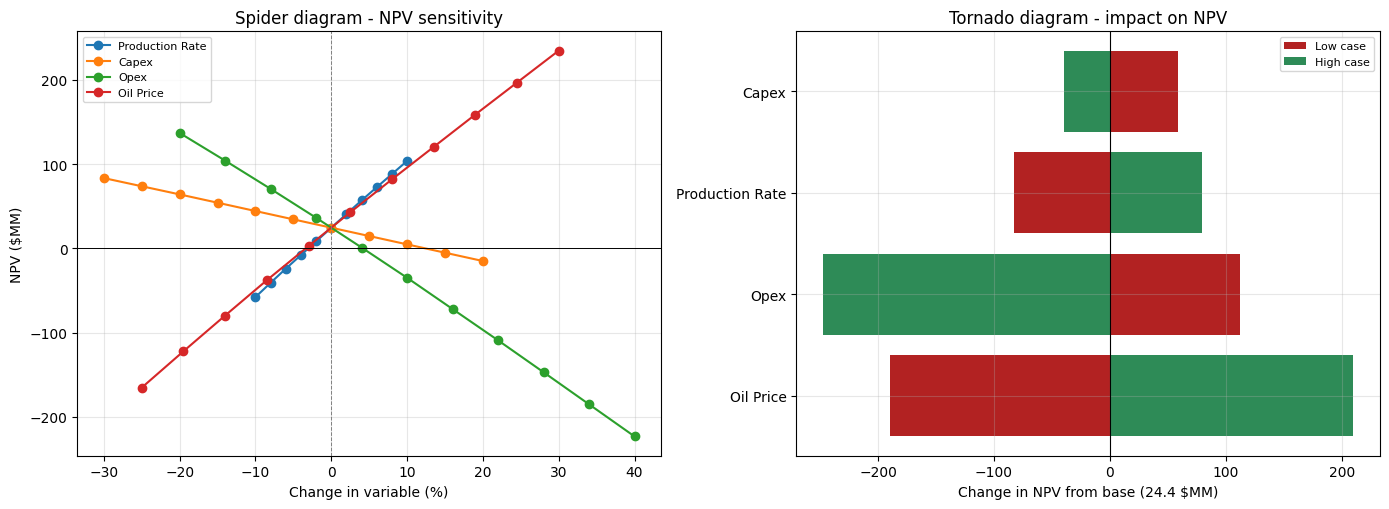

In [16]:
_MULT_MAP = {"Production Rate": "prod", "Capex": "capex", "Opex": "opex", "Oil Price": "price"}
best_p = alternatives[recommendation]
sens_rows, spider = [], {}
for label, (lo, hi) in base_inputs.sens.items():
    key = _MULT_MAP.get(label)
    if key is None:
        continue
    npv_lo = evaluate(build_cash_flow(best_p, mult={key: 1 + lo}), DISC)["NPV"]
    npv_hi = evaluate(build_cash_flow(best_p, mult={key: 1 + hi}), DISC)["NPV"]
    sens_rows.append({"Variable": label, "Low case": f"{lo:+.0%}", "NPV @ low": npv_lo,
                      "High case": f"{hi:+.0%}", "NPV @ high": npv_hi, "Range ($MM)": abs(npv_hi - npv_lo)})
    grid = np.linspace(min(lo, 0), max(hi, 0), 11)
    spider[label] = (grid, [evaluate(build_cash_flow(best_p, mult={key: 1 + g}), DISC)["NPV"] for g in grid])

sens_df = pd.DataFrame(sens_rows).set_index("Variable").sort_values("Range ($MM)", ascending=False)
print(f"Sensitivity of NPV for the recommended case ({recommendation}), base NPV = {best_p and evaluate(build_cash_flow(best_p), DISC)['NPV']:.2f} $MM:")
display(sens_df.round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for label, (grid, vals) in spider.items():
    ax[0].plot(grid * 100, vals, "o-", label=label)
ax[0].axhline(0, color="k", lw=0.7); ax[0].axvline(0, color="gray", lw=0.7, ls="--")
ax[0].set(title="Spider diagram - NPV sensitivity", xlabel="Change in variable (%)", ylabel="NPV ($MM)"); ax[0].legend(fontsize=8)

order = sens_df.index
base_val = evaluate(build_cash_flow(best_p), DISC)["NPV"]
lo_vals = sens_df["NPV @ low"].values - base_val
hi_vals = sens_df["NPV @ high"].values - base_val
y = np.arange(len(order))
ax[1].barh(y, lo_vals, color="firebrick", label="Low case")
ax[1].barh(y, hi_vals, color="seagreen", label="High case")
ax[1].axvline(0, color="k", lw=0.8); ax[1].set_yticks(y); ax[1].set_yticklabels(order)
ax[1].set(title="Tornado diagram - impact on NPV", xlabel=f"Change in NPV from base ({base_val:.1f} $MM)")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 17. Export results
Every table produced above is written to a multi-sheet Excel workbook so the analysis can be shared or audited outside Python.

In [17]:
if CONFIG["SAVE_RESULTS"]:
    with pd.ExcelWriter(CONFIG["RESULTS_FILE"], engine="openpyxl") as xl:
        base_cf.round(4).to_excel(xl, sheet_name="Base Cash Flow", index=False)
        screening_table(base_metrics, DISC).to_excel(xl, sheet_name="Base Indicators", index=False)
        startup_df.round(4).to_excel(xl, sheet_name="Startup Delay")
        summary_df.round(4).to_excel(xl, sheet_name="Alternatives")
        inc_table.round(4).to_excel(xl, sheet_name="Incremental Analysis", index=False)
        comparison.round(4).to_excel(xl, sheet_name="Final Comparison")
        sens_df.round(4).to_excel(xl, sheet_name="Sensitivity")
        pd.DataFrame([{"Recommendation": recommendation, "Discount rate": DISC,
                       "Capital budget": CONFIG["CAPITAL_BUDGET"]}]).to_excel(xl, sheet_name="Summary", index=False)
    print(f"Results workbook written: {os.path.abspath(CONFIG['RESULTS_FILE'])}")
    print("Sheets: Base Cash Flow, Base Indicators, Startup Delay, Alternatives, "
         "Incremental Analysis, Final Comparison, Sensitivity, Summary")
else:
    print("CONFIG['SAVE_RESULTS'] is False -> no file written.")

Results workbook written: /content/Economic_Indicators_Results.xlsx
Sheets: Base Cash Flow, Base Indicators, Startup Delay, Alternatives, Incremental Analysis, Final Comparison, Sensitivity, Summary


## 18. Save all output to the folder
Writes the remaining files into the output folder created in Section 2b (next to your Excel dataset): all the **cash-flow tables** (every alternative and every start-up case) in one workbook, a **copy of the dataset** used for the run, then restores normal output and closes the log. The results workbook from Section 17 is already in the same folder.

In [ ]:
# ---- extra workbook: full cash flows of every alternative and every start-up delay ----
_cf_path = os.path.join(OUTPUT_DIR, "All_Cash_Flows.xlsx")
with pd.ExcelWriter(_cf_path, engine="openpyxl") as xl:
    for label, cf_ in globals().get("alt_cf", {}).items():
        cf_.round(4).to_excel(xl, sheet_name=("Alt " + _slug(label))[:31], index=False)
    for delay, cf_ in globals().get("startup_cfs", {}).items():
        cf_.round(4).to_excel(xl, sheet_name=f"Delay {delay} yr", index=False)
    if not (globals().get("alt_cf") or globals().get("startup_cfs")):
        base_cf.round(4).to_excel(xl, sheet_name="Base Cash Flow", index=False)

# ---- keep a copy of the input dataset with the results ----
try:
    shutil.copy2(DATASET_PATH, os.path.join(OUTPUT_DIR, "input_" + os.path.basename(DATASET_PATH)))
except Exception as e:
    print(f"(Could not copy dataset: {e})")

# ---- list what was saved, then close the log and restore normal output ----
print(f"\nAll output saved in: {OUTPUT_DIR}")
for root, _, names in os.walk(OUTPUT_DIR):
    for n in sorted(names):
        print("  " + os.path.relpath(os.path.join(root, n), OUTPUT_DIR))

sys.stdout = _orig_stdout
_log_file.close()
plt.show = _orig_show
display = _orig_display
print("Output hooks removed; run_log.txt closed.")

# ---- zip ALL output and let the user choose where the zip file is saved ----
import zipfile, tempfile

_zip_name = f"{_stem}_output.zip"
_tmp_zip = os.path.join(tempfile.mkdtemp(), _zip_name)          # built outside OUTPUT_DIR so it never zips itself
with zipfile.ZipFile(_tmp_zip, "w", zipfile.ZIP_DEFLATED) as _zf:
    for _root, _, _names in os.walk(OUTPUT_DIR):
        for _n in sorted(_names):
            _full = os.path.join(_root, _n)
            _zf.write(_full, os.path.join(os.path.basename(OUTPUT_DIR), os.path.relpath(_full, OUTPUT_DIR)))


def choose_zip_location(default_name):
    '''Ask the user where to save the zip.  Tries, in order:
       1) Google Colab -> browser download (the browser lets you pick the folder),
       2) native "Save as" dialog, 3) typed path.  Returns the saved path (or None for Colab download).'''
    print("=" * 70)
    print(" CHOOSE WHERE TO SAVE THE ZIP FILE WITH ALL OUTPUT")
    print("=" * 70)

    # 1) Google Colab -> download through the browser
    try:
        from google.colab import files
        files.download(_tmp_zip)
        print(f"Download started for {default_name} (your browser decides / asks for the save location).")
        return None
    except ImportError:
        pass

    # 2) Desktop -> native "Save as" dialog
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        path = filedialog.asksaveasfilename(
            title="Choose where to save the zip file with all output",
            initialfile=default_name, defaultextension=".zip",
            filetypes=[("Zip archive", "*.zip")])
        root.destroy()
        if path:
            return path
        print("No location chosen in the dialog.")
    except Exception:
        print("(Save dialog not available in this environment - please type the location.)")

    # 3) Fallback -> typed folder or full file path
    while True:
        path = input("Folder (or full .zip path) to save into (or 'q' to skip): ").strip().strip('"').strip("'")
        if path.lower() in ("q", "quit", "exit"):
            return ""
        path = os.path.expanduser(path)
        if os.path.isdir(path):
            return os.path.join(path, default_name)
        if path.lower().endswith(".zip") and os.path.isdir(os.path.dirname(os.path.abspath(path))):
            return path
        print(f"  Not a valid folder / .zip path: {path!r}. Try again.")


_zip_target = choose_zip_location(_zip_name)
if _zip_target:
    shutil.copy2(_tmp_zip, _zip_target)
    print(f"\nZip file with all output saved to: {os.path.abspath(_zip_target)}")
elif _zip_target == "":
    print(f"\nNo location selected. The zip file was left at: {_tmp_zip}")
